## Context

This notebook accompanies User Guide section 7 (Three-tier extraction).  It runs `extract_from_tool` over a synthetic `train_model` raw_result and over the matching display string, then compares Tier 1 (deterministic dict-read) with Tier 3 (structured-text / LLM-equivalent parser) on the same input.  The takeaway is: when a structured `raw_result` is available, Tier 1 is byte-deterministic; Tier 3 is lossy because display strings are formatted for human consumption.

In [1]:
# Phase 2 preamble: bootstrap runtime + load shared helpers
import sys
import os
import glob
import warnings
warnings.filterwarnings('ignore')
for _p in glob.glob(
        '/home/asudjianto/cluster/spark-venv/lib/python*/site-packages'):
    if _p not in sys.path:
        sys.path.insert(0, _p)
_REPO = os.path.expanduser('~/jupyterlab/kg-memory')
if _REPO not in sys.path:
    sys.path.insert(0, _REPO)

from user_guide_tutorials.notebooks import _helpers_phase1 as h1
h1.bootstrap_runtime()
from user_guide_tutorials.notebooks import _shared as ug
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')


Device: cuda, CUDA available: True


### Concept: tier order matches accuracy order

Every governed-agent tool returns the dual-return pattern: `(display_string, raw_dict)`.  The dispatcher in `governed_agent.extractors.extract_from_tool` tries Tier 1 first when `raw_result` is a non-empty dict and a Tier 1 extractor is registered for `tool_name`.  It falls through to Tier 2 (regex on display string) only if Tier 1 produces no facts, and to Tier 3 (structured-text / LLM parser) only if Tier 2 also produces nothing.

Tier 1 is 100% accurate on registered tools because it reads the raw dict directly.  Tier 3 reaches only 58 to 65% on tabular and nested-dict inputs in the FinStructBench benchmark documented in `gms_agent_builder_ext/chapters/ch04.tex` §4.2 — display strings are formatted for human consumption, so an LLM must reverse-engineer the structure.  The cost of skipping Tier 1 is therefore real, not theoretical.

Below we run `extract_from_tool` twice over the same `train_model` output: once with the `raw_result` dict (forcing Tier 1) and once with only the display string (forcing Tier 3).  We then compare counts and check that the ground-truth accuracy of 0.95 round-trips through Tier 1.  Tier 3 is exercised through the deterministic `extract_triples_simple` parser so the assertion runs regardless of API-key state.

In [ ]:
from knowlytix.harness.governance.extractors import (
    extract_from_tool,
)

# Synthetic train_model dual-return
tool_args = {
    'model_type': 'RandomForestClassifier',
    'model_name': 'rf_iris',
    'dataset': 'iris',
}
raw_result = {
    'model_name': 'rf_iris',
    'model_type': 'RandomForestClassifier',
    'metrics': {
        'accuracy': 0.95,
        'f1': 0.94,
        'precision': 0.93,
        'recall': 0.95,
    },
}
display_string = (
    'Trained rf_iris (RandomForestClassifier) on iris\n'
    'metrics: accuracy: 0.95, f1: 0.94, '
    'precision: 0.93, recall: 0.95\n'
)
ground_truth = {
    'accuracy': 0.95, 'f1': 0.94,
    'precision': 0.93, 'recall': 0.95,
}
print('Inputs prepared.')


In [3]:
# Tier 1: deterministic dict-read
tier1_result = extract_from_tool(
    tool_name='train_model',
    args=tool_args,
    raw_result=raw_result,
    display_string='',
)
tier1_triples = tier1_result.triples
print(f'Tier {tier1_result.tier}: '
      f'{len(tier1_triples)} triples, '
      f'{len(tier1_result.enm_entries)} ENM entries')
for t in tier1_triples[:6]:
    nv = '' if t.numeric_value is None else f' ({t.numeric_value})'
    print(f'  ({t.head}, {t.relation}, {t.tail}){nv}')


Tier 1: 6 triples, 4 ENM entries
  (rf_iris, is_type, RandomForestClassifier)
  (rf_iris, trained_on, iris)
  (rf_iris, has_accuracy, 0.95) (0.95)
  (rf_iris, has_f1, 0.94) (0.94)
  (rf_iris, has_precision, 0.93) (0.93)
  (rf_iris, has_recall, 0.95) (0.95)


In [ ]:
# Tier 3 (structured-text parser, deterministic stand-in for LLM):
# force the cascade to skip Tier 1 by passing raw_result=None and
# the display_string only. Tier 2 regex extracts the metrics; if it
# fires we still get a useful comparison.  In production with
# ANTHROPIC_API_KEY set, swap in docgms.extract.extract_triples()
# for true Tier 3.
from knowlytix.harness.governance.extractors import tier3_extract

tier3_result = tier3_extract(
    tool_name='train_model',
    args=tool_args,
    display_string=display_string,
)
tier3_triples = tier3_result.triples
print(f'Tier {tier3_result.tier}: '
      f'{len(tier3_triples)} triples, '
      f'{len(tier3_result.enm_entries)} ENM entries')
for t in tier3_triples[:6]:
    nv = '' if t.numeric_value is None else f' ({t.numeric_value})'
    print(f'  ({t.head}, {t.relation}, {t.tail}){nv}')


In [ ]:
# Cross-check Tier 1 numeric values against ground truth
from knowlytix.harness.governance.extractors import compare_extraction_accuracy

tier1_check = compare_extraction_accuracy(
    ground_truth, tier1_result,
)
tier3_check = compare_extraction_accuracy(
    ground_truth, tier3_result,
)
print(f'Tier 1 accuracy vs ground truth: {tier1_check["accuracy"]} '
      f'(matched={tier1_check["matched"]}, '
      f'mismatched={tier1_check["mismatched"]}, '
      f'missing={tier1_check["missing"]})')
print(f'Tier 3 accuracy vs ground truth: {tier3_check["accuracy"]} '
      f'(matched={tier3_check["matched"]}, '
      f'mismatched={tier3_check["mismatched"]}, '
      f'missing={tier3_check["missing"]})')


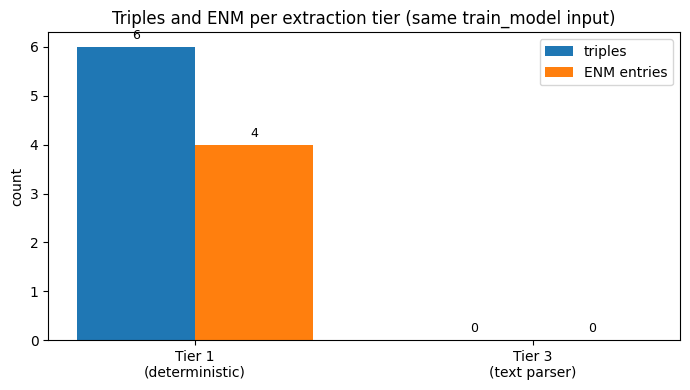

In [6]:
# Visualization: side-by-side bar showing triples per tier
import matplotlib.pyplot as plt

tiers = ['Tier 1\n(deterministic)', 'Tier 3\n(text parser)']
n_triples = [len(tier1_triples), len(tier3_triples)]
n_enm = [len(tier1_result.enm_entries),
         len(tier3_result.enm_entries)]
x = list(range(len(tiers)))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([xi - width / 2 for xi in x], n_triples, width,
       color='tab:blue', label='triples')
ax.bar([xi + width / 2 for xi in x], n_enm, width,
       color='tab:orange', label='ENM entries')
for xi, t, e in zip(x, n_triples, n_enm):
    ax.text(xi - width / 2, t + 0.1, str(t),
            ha='center', va='bottom', fontsize=9)
    ax.text(xi + width / 2, e + 0.1, str(e),
            ha='center', va='bottom', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(tiers)
ax.set_ylabel('count')
ax.set_title('Triples and ENM per extraction tier '
             '(same train_model input)')
ax.legend(loc='upper right')
fig.tight_layout()
plt.show()


### Exercises

1. Pass an `args` dict missing the `model_name` key and re-run Tier 1.  The deterministic extractor falls back to `raw_result['model_name']`; confirm the triples still land.
2. Inject a typo into the display string (`accuracy: 0.95` becomes `accuracy = 0.95`) and re-run Tier 3.  Observe how many triples drop.
3. Read `governed_agent/extractors.py:_TIER1_EXTRACTORS` and list the six tools currently registered.  Pick one (`leaderboard`) and write a synthetic `raw_result` for it; run Tier 1 and read the resulting triples.

### What you should now be able to do

- Call `extract_from_tool` over a `(display, raw_dict)`   pair and read the resulting `ExtractionResult`.
- Force Tier 1 by passing `raw_result`; force Tier 3 by   passing `raw_result=None`.
- Recite the FinStructBench finding: Tier 1 is 100% on   structured tool output; Tier 3 reaches 58 to 65%.
- Use `compare_extraction_accuracy` to cross-check   numeric values against a ground-truth dict.

### Cross-references

- USER_GUIDE.md section 7 (Three-tier extraction)
- `governed_agent/extractors.py` for the Tier 1 dispatch   table and the `extract_from_tool` cascade
- `docgms/extract.py:extract_triples_simple` and   `docgms/extract.py:extract_triples`
- `gms_agent_builder_ext/chapters/ch04.tex` §4.2-4.3 for   the FinStructBench accuracy figures

In [7]:
# Final assertion: Tier 1 produces at least the expected
# minimum count for train_model.  The registered extractor
# yields 2 base triples + 4 metric triples = 6 minimum.
assert len(tier1_triples) >= 6, (
    f'Tier 1 should produce >= 6 triples on a 4-metric '
    f'train_model input; got {len(tier1_triples)}'
)
# Tier 1 must also be perfectly accurate on ground truth
assert tier1_check['accuracy'] == 1.0, (
    f'Tier 1 accuracy regressed: {tier1_check}'
)
print(f'OK: Tier 1 emitted {len(tier1_triples)} triples, '
      f'accuracy={tier1_check["accuracy"]}; '
      f'Tier 3 emitted {len(tier3_triples)} triples, '
      f'accuracy={tier3_check["accuracy"]}.')


OK: Tier 1 emitted 6 triples, accuracy=1.0; Tier 3 emitted 0 triples, accuracy=0.0.
